In [1]:
!pip install tensorflow scikit-learn matplotlib seaborn -q

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Select required samples
X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (10000, 28, 28)
Testing data: (2000, 28, 28)


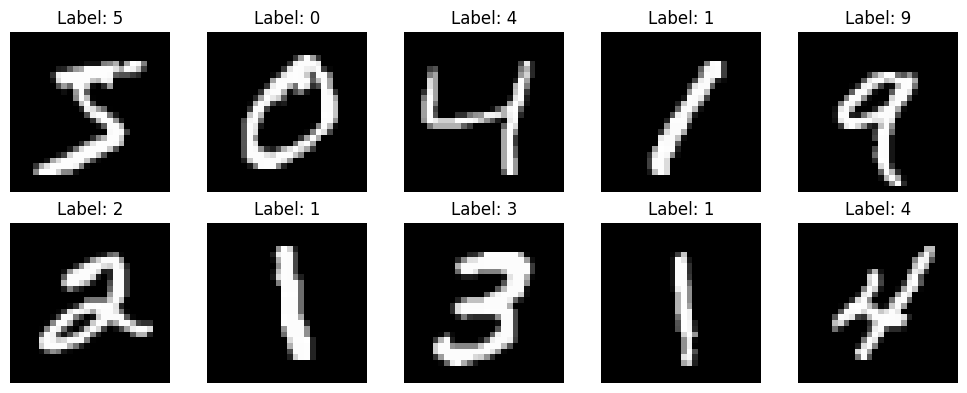

In [4]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Flatten images
X_train_flat = X_train.reshape(10000, 784)
X_test_flat = X_test.reshape(2000, 784)

# Normalize pixel values
X_train_flat = X_train_flat.astype('float32') / 255.0
X_test_flat = X_test_flat.astype('float32') / 255.0

print("Training shape:", X_train_flat.shape)
print("Testing shape:", X_test_flat.shape)

Training shape: (10000, 784)
Testing shape: (2000, 784)


In [6]:
model = Sequential([
    Input(shape=(784,)),

    Dense(128, activation='relu'),
    Dense(128, activation='relu'),
    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,794 (526.54 KB)

 Trainable params: 134,794 (526.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
start_time = time.time()

history = model.fit(
    X_train_flat,
    y_train,
    epochs=3,
    batch_size=128,
    validation_data=(X_test_flat, y_test),
    verbose=1
)

mlp_time = time.time() - start_time

print("MLP Training Time:", round(mlp_time, 2), "seconds")

Epoch 1/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.7907 - loss: 0.7410 - val_accuracy: 0.8775 - val_loss: 0.4135
Epoch 2/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9242 - loss: 0.2612 - val_accuracy: 0.9000 - val_loss: 0.3052
Epoch 3/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9497 - loss: 0.1793 - val_accuracy: 0.9150 - val_loss: 0.2655
MLP Training Time: 13.5 seconds


In [8]:
test_loss, test_accuracy = model.evaluate(
    X_test_flat,
    y_test,
    verbose=0
)

print("MLP Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("MLP Test Loss:", round(test_loss, 4))

MLP Test Accuracy: 91.5 %
MLP Test Loss: 0.2655


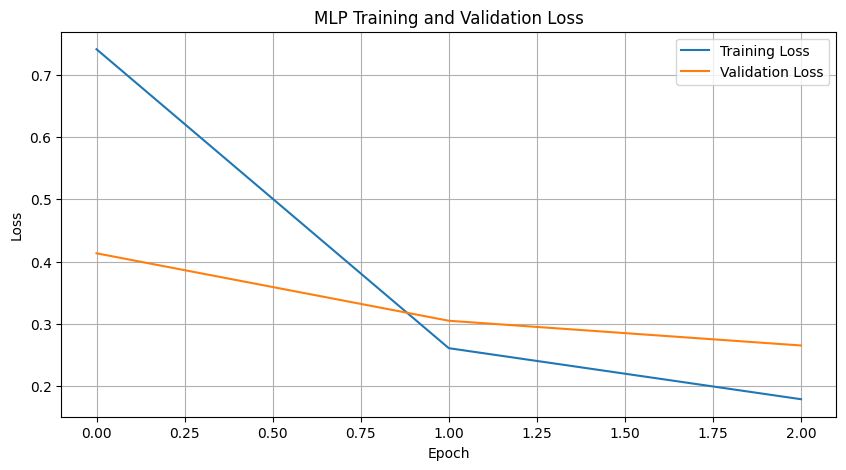

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

In [10]:
lr_model = LogisticRegression(
    max_iter=100,
    solver='lbfgs'
)

start_time = time.time()

lr_model.fit(X_train_flat, y_train)

lr_time = time.time() - start_time

lr_predictions = lr_model.predict(X_test_flat)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Training Time:",
      round(lr_time, 2), "seconds")

Logistic Regression Accuracy: 87.1 %
Training Time: 9.9 seconds


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [11]:
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=20,
    random_state=42
)

start_time = time.time()

dt_model.fit(X_train_flat, y_train)

dt_time = time.time() - start_time

dt_predictions = dt_model.predict(X_test_flat)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

print("Training Time:",
      round(dt_time, 2), "seconds")

Decision Tree Accuracy: 77.3 %
Training Time: 2.42 seconds


In [12]:
models = ['MLP', 'Logistic Regression', 'Decision Tree']

accuracies = [
    test_accuracy * 100,
    lr_accuracy * 100,
    dt_accuracy * 100
]

training_times = [
    mlp_time,
    lr_time,
    dt_time
]

results = {
    'Model': models,
    'Accuracy (%)': accuracies,
    'Training Time (seconds)': training_times
}

import pandas as pd

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy (%)  Training Time (seconds)
0                  MLP     91.500002                13.496929
1  Logistic Regression     87.100000                 9.898277
2        Decision Tree     77.300000                 2.417979


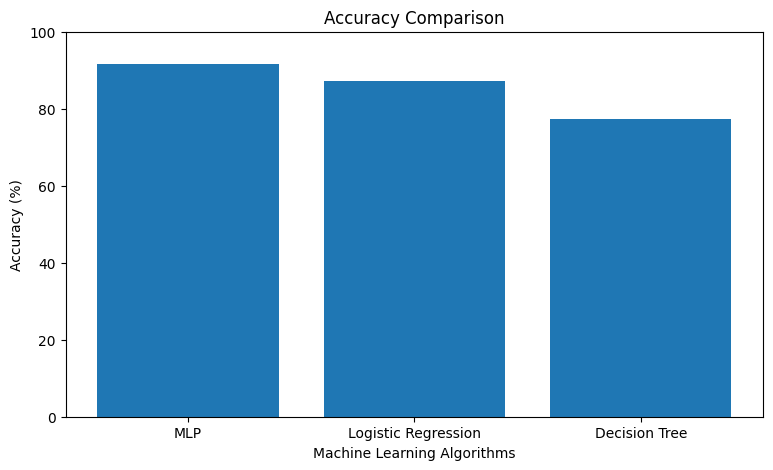

In [13]:
plt.figure(figsize=(9, 5))

plt.bar(models, accuracies)

plt.title("Accuracy Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.show()

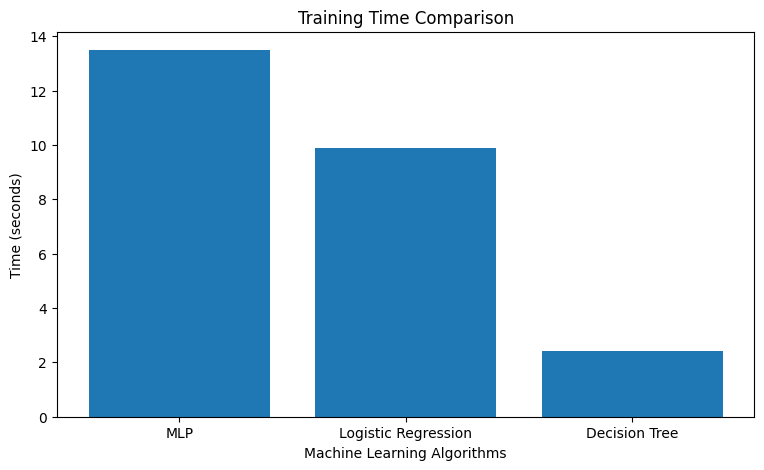

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(models, training_times)

plt.title("Training Time Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Time (seconds)")

plt.show()

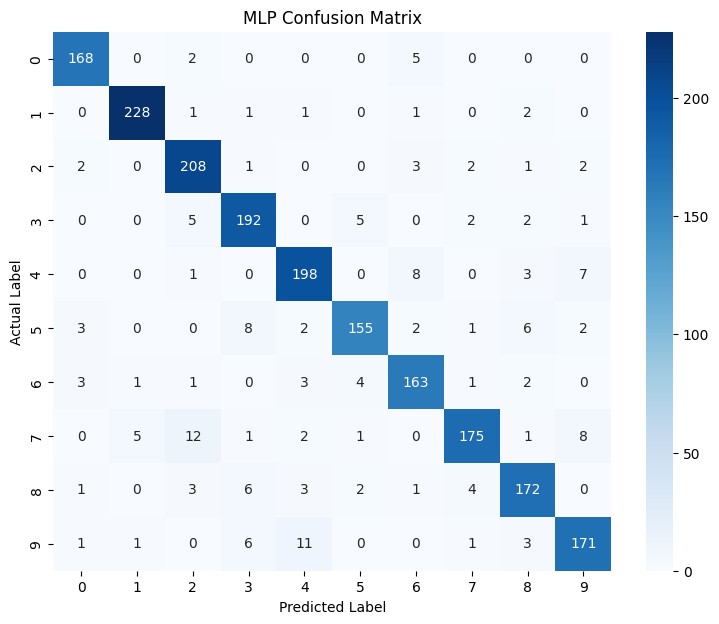

In [15]:
mlp_predictions = np.argmax(
    model.predict(X_test_flat, verbose=0),
    axis=1
)

cm = confusion_matrix(y_test, mlp_predictions)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("MLP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [16]:
print("MLP Classification Report")

print(
    classification_report(
        y_test,
        mlp_predictions
    )
)

MLP Classification Report
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       175
           1       0.97      0.97      0.97       234
           2       0.89      0.95      0.92       219
           3       0.89      0.93      0.91       207
           4       0.90      0.91      0.91       217
           5       0.93      0.87      0.90       179
           6       0.89      0.92      0.90       178
           7       0.94      0.85      0.90       205
           8       0.90      0.90      0.90       192
           9       0.90      0.88      0.89       194

    accuracy                           0.92      2000
   macro avg       0.92      0.91      0.91      2000
weighted avg       0.92      0.92      0.91      2000



In [17]:
print("FINAL MODEL COMPARISON")
print("-" * 45)

for i in range(3):
    print(models[i])
    print("Accuracy:", round(accuracies[i], 2), "%")
    print("Training Time:", round(training_times[i], 2), "seconds")
    print("-" * 45)

best_model = models[np.argmax(accuracies)]

print("Best Performing Model:", best_model)

FINAL MODEL COMPARISON
---------------------------------------------
MLP
Accuracy: 91.5 %
Training Time: 13.5 seconds
---------------------------------------------
Logistic Regression
Accuracy: 87.1 %
Training Time: 9.9 seconds
---------------------------------------------
Decision Tree
Accuracy: 77.3 %
Training Time: 2.42 seconds
---------------------------------------------
Best Performing Model: MLP
